## Single Sample Prediction Using Decision Trees (Gini & Entropy)

In [28]:
import seaborn as sns
from sklearn.tree import DecisionTreeClassifier
import pandas as pd

iris = sns.load_dataset("iris")
x = iris.drop("species", axis = 1)
y = iris["species"]
iris.head()

new_data = pd.DataFrame([[5, 4, 3, 2],[2,7,1,9]], columns=x.columns)

model_gini = DecisionTreeClassifier(criterion = "gini")
model_gini.fit(x,y)

prediction_gini = model_gini.predict(new_data)

model_entropy = DecisionTreeClassifier(criterion = "entropy")
model_entropy.fit(x,y)

prediction_entropy = model_entropy.predict(new_data)

print("First data - Gini:", prediction_gini[0])
print("First data - Entropy:", prediction_entropy[0])

print("Second data - Gini:", prediction_gini[1])
print("Second data - Entropy:", prediction_entropy[1])

First data - Gini: versicolor
First data - Entropy: versicolor
Second data - Gini: setosa
Second data - Entropy: setosa


## Predicting Class Probabilities

In [30]:
import seaborn as sns
import pandas as pd
from sklearn.tree import DecisionTreeClassifier

iris = sns.load_dataset("iris")
x = iris.drop("species", axis = 1)
y = iris["species"]

new_data = pd.DataFrame([[5, 4, 3, 2]], columns=x.columns)

model_gini = DecisionTreeClassifier(criterion = "gini")
model_gini.fit(x,y)

prediction_gini = model_gini.predict(new_data)

model_entropy = DecisionTreeClassifier(criterion = "entropy")
model_entropy.fit(x,y)

prediction_entropy = model_entropy.predict(new_data)

gini_prob = model_gini.predict_proba(new_data)[0]
entropy_prob = model_entropy.predict_proba(new_data)[0]

results = pd.DataFrame({
    "Species": model_gini.classes_,
    "Gini Probability": gini_prob,
    "Entropy Probability": entropy_prob
})
print(results)

      Species  Gini Probability  Entropy Probability
0      setosa               0.0                  0.0
1  versicolor               1.0                  1.0
2   virginica               0.0                  0.0


## Decision Tree Visualization

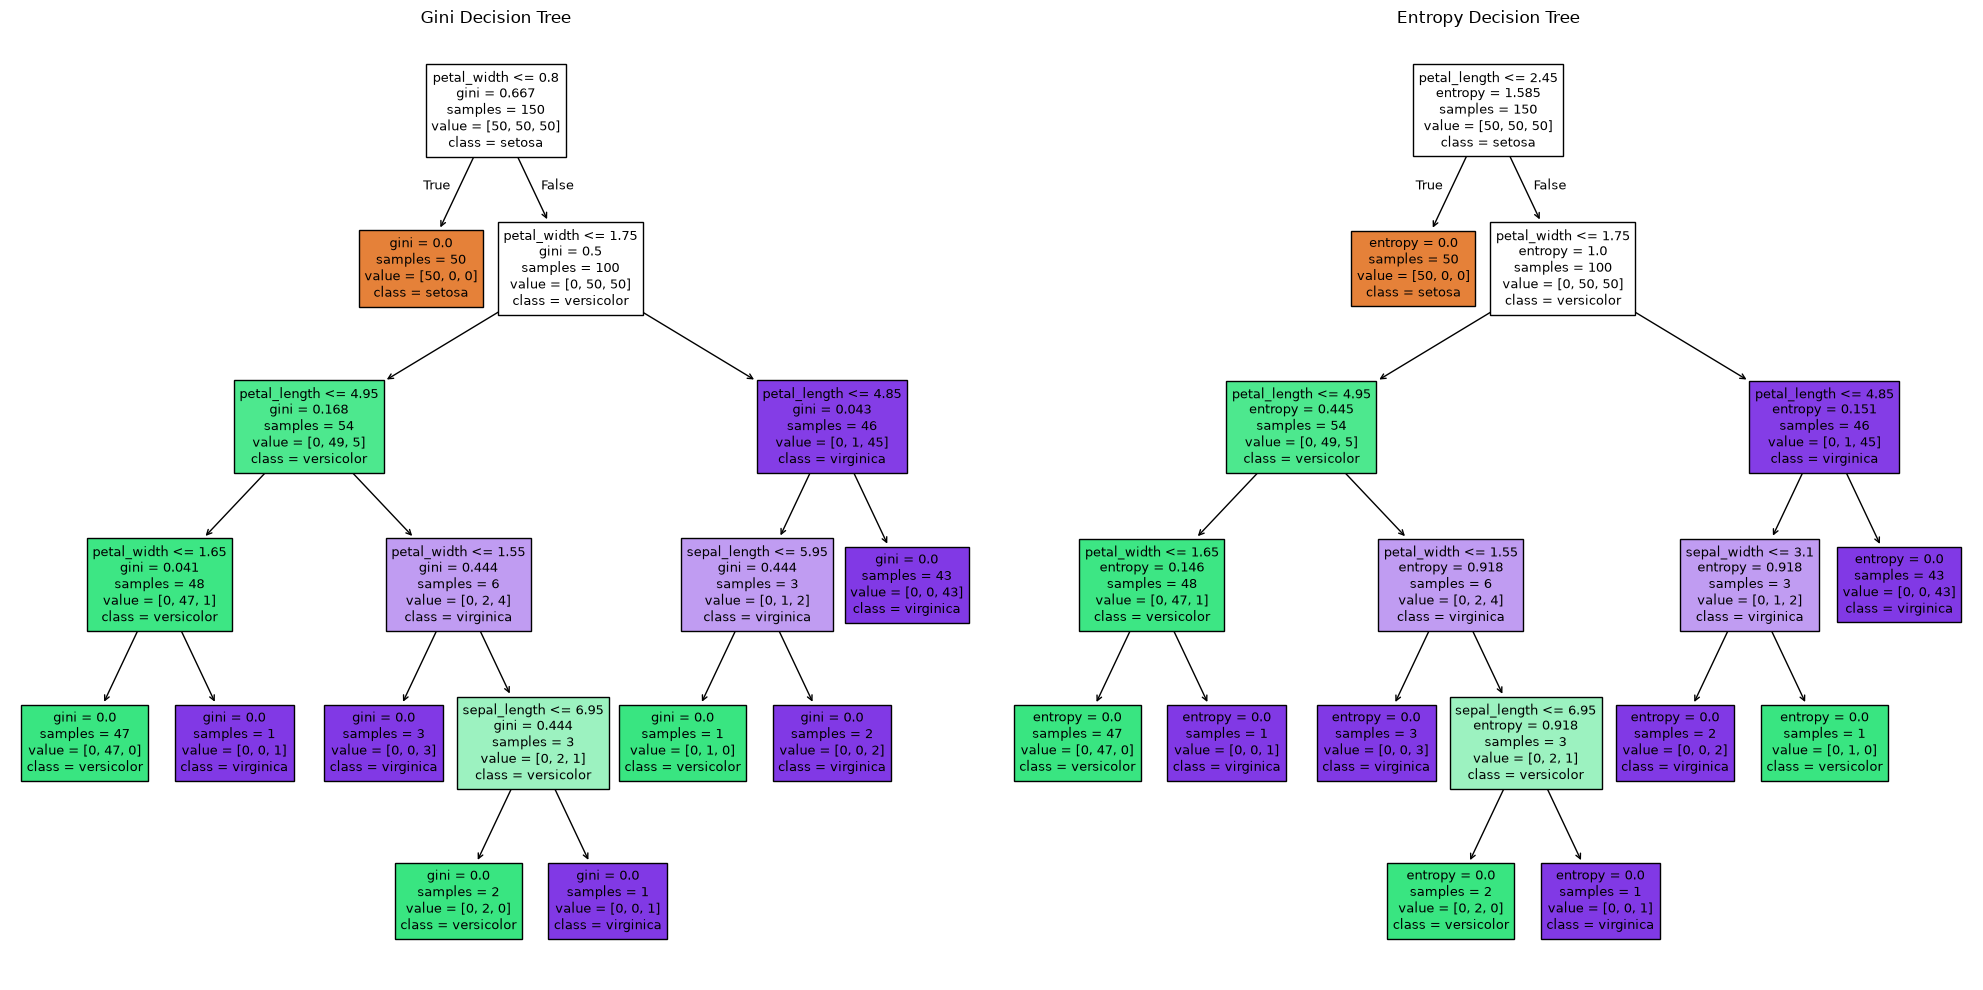

In [39]:
import seaborn as sns
from sklearn.tree import DecisionTreeClassifier
import matplotlib.pyplot as plt
from sklearn.tree import plot_tree

iris = sns.load_dataset("iris")
x = iris.drop("species", axis = 1)
y = iris["species"]
iris.head()

model_entropy = DecisionTreeClassifier(criterion = "entropy")
model_entropy.fit(x,y)

model_gini = DecisionTreeClassifier(criterion = "gini")
model_gini.fit(x,y)

fig, axes = plt.subplots(1,2, figsize=(20, 10))
plot_tree(
    model_gini,
    feature_names=x.columns,
    class_names=model_gini.classes_,
    filled=True,
    fontsize=9,
    ax = axes[0]
)
axes[0].set_title("Gini Decision Tree")
plot_tree(
    model_entropy,
    feature_names=x.columns,
    class_names=model_gini.classes_,
    filled=True,
    fontsize=9,
    ax = axes[1]
)
axes[1].set_title("Entropy Decision Tree")
plt.tight_layout()
plt.show()


## Decision Tree Regression Using MSE and MAE

In [50]:
import pandas as pd
from sklearn.datasets import fetch_openml
from sklearn.tree import DecisionTreeRegressor

# Load Boston Housing dataset
boston = fetch_openml(
    name="boston", version=1, as_frame=True
)

df = boston.frame
df.head()

x = df[["CRIM","ZN"]]
y = df["MEDV"]

new_data = pd.DataFrame([[0.02, 16]], columns=x.columns)

mse_model = DecisionTreeRegressor(criterion="squared_error", random_state=61)
mae_model = DecisionTreeRegressor(criterion="absolute_error", random_state=61)

mse_model.fit(x,y)
mae_model.fit(x,y)

pred_mse= mse_model.predict(new_data)
pred_mae= mae_model.predict(new_data)

print("MSE Prediction: ", pred_mse[0])
print("MAE Prediction: ", pred_mae[0])


MSE Prediction:  33.0
MAE Prediction:  33.0


## Classification Using Random Forest

In [66]:
import seaborn as sns
from sklearn.ensemble import RandomForestClassifier
import matplotlib.pyplot as plt
from sklearn.tree import plot_tree

iris = sns.load_dataset("iris")
x = iris.drop("species", axis = 1)
y = iris["species"]
iris.head()

model_random = RandomForestClassifier(n_estimators=100, random_state=61)#n_estimators sayısı kadar decision tree oluşturur.
model_random.fit(x,y)

new_data = pd.DataFrame([[5, 4, 3, 2]], columns= x.columns)

pred_rnd = model_random.predict(new_data)
print("RandomForest: ",pred_rnd[0])

for i, tree in enumerate(model_random.estimators_[:5]):
    pred = tree.predict(new_data.to_numpy())[0]
    print(f"Tree {i+1}: {model_random.classes_[int(pred)]}")#classlar sayısal index ile temsil edildiği için böyle yazıyoruz


RandomForest:  versicolor
Tree 1: versicolor
Tree 2: versicolor
Tree 3: virginica
Tree 4: virginica
Tree 5: versicolor


## Random Forest Regression and Averaging Tree Predictions

## Feature Importance Visualization

## Classification with Imbalanced Classes